<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">
<br>

<h1 style="text-align:center">Datathon Task 1: Peramalan Kecepatan Lalu Lintas</h1>
<h3 style="text-align:center">TrafficCast v3: Residual LightGBM per Regime di atas Anchor Mean-Reversion per Ruas</h3>

<p style="text-align:center; color:gray">Iterasi final. v1 (LightGBM raw) = 41.795, v2 (Residual Graph-STID) = 39.256. Target v3: mendekati 34.225 (peringkat 1).</p>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

# Daftar Isi
1. [**Pendahuluan dan Strategi**](#1)
2. [**Konfigurasi**](#2)
3. [**Setup dan Path Data**](#3)
4. [**Muat Data dan Validasi Integritas**](#4)
5. [**Regime Routing m1/m2**](#5)
6. [**Statistik Ruas dan Anchor Mean-Reversion**](#6)
7. [**Fitur Teks Atomik**](#7)
8. [**Pembangun Fitur Bersama**](#8)
9. [**Validasi Silang 3 Fold**](#9)
10. [**Gerbang Validasi Submisi**](#10)
11. [**Pelatihan Final dan Submission**](#11)
12. [**Kesimpulan dan Daftar Pustaka**](#12)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="1"></a>
# **1. Pendahuluan dan Strategi**

Notebook ini adalah iterasi ketiga (v3) untuk Task 1: memprediksi kecepatan 1.260 ruas jalan pada horizon +20/+40/+60 menit (`h5`, `h10`, `h15`) dari 15 langkah riwayat, dengan metrik *MSE*.

Desain v3 bukan hasil eksplorasi baru, melainkan sintesis dari audit data dan probe empiris yang sudah divalidasi pada sesi riset sebelumnya:

| Bukti empiris (CV 3 fold tertimbang) | Skor |
| --- | --- |
| *Persistence* | 53.29 |
| Rata-rata 15 langkah terakhir (proxy v1) | 41.72 |
| *Anchor mean-reversion* per ruas | 40.35 |
| *Anchor* + fitur temporal lokal (*ridge*) | 37.54 |
| *Anchor* + lokal + *global network state* (*ridge*) | **35.42** |

Temuan kunci yang diimplementasikan langsung:

1. **Regime m1/m2 sangat berbeda** (Wilcoxon p sampai 7.1e-41): rasio nol 1.0% vs 16.7%, 210 ruas selalu nol di m2, koefisien *mean-reversion* berbeda. Semua statistik, *anchor*, dan model dipisah per regime, dengan *routing* sampel test lewat fraksi nol (celah pemisah sangat bersih: 0.0206 vs 0.1667).
2. **Target residual, bukan kecepatan mentah.** Model LightGBM memprediksi selisih terhadap *anchor* `road_mean + c_road_h * (last - road_mean)` per ruas per horizon, sehingga kapasitas model fokus pada sinyal yang belum tertangkap *baseline*.
3. **Fitur lokal + global adalah sinyal terbesar** (35.42 dengan *ridge* saja). Fitur graf hampir nol kontribusi setelah lokal+global ada (38.30198 vs 38.30222 pada probe), jadi hanya disertakan 2 kolom *neighbor anomaly* murah. *Time-of-day* ditolak: inferensi fase tidak andal (galat median sampai 27 langkah).
4. **Aturan nol tervalidasi kuat**: P(target=0 | lag0=0) > 99.78%. Baris dengan kecepatan terakhir nol tidak dilatih dan dipulihkan sebagai nol saat inferensi.
5. **Test m2-like menyerupai m2 periode akhir** (jarak distribusi 0.85 vs 4.98 untuk periode awal), sehingga model m2 memakai bobot sampel yang menekankan periode akhir.
6. **Teks cukup 10 kata kunci atomik** (cakupan >99.9% kalimat). *TF-IDF*, *embedding*, dan pasangan event-lokasi ditolak berdasarkan audit teks.
7. **Identitas ruas penting** (sejalan ide *identity embedding* pada makalah STID): `road_id` kategorikal, koordinat grid 36x36 dari `active_mask`, dan metadata agregat seluruh *link* per ruas.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="2"></a>
# **2. Konfigurasi**

Satu kelas konfigurasi terpusat. `RUN_MODE`:
- `smoke`: validasi pipa ujung ke ujung dengan subset kecil, selesai beberapa menit, tanpa *submission*.
- `cv`: validasi silang penuh saja, tanpa *training* final.
- `final`: validasi silang penuh, gerbang validasi, *training* final di seluruh data, tulis `submission.csv`.

In [1]:
class CFG:
    RUN_MODE = 'final'            # 'smoke' | 'cv' | 'final'
    DATA_DIR = None               # None berarti deteksi otomatis (Kaggle atau lokal)
    WORK_DIR = None
    SEED = 42

    HISTORY = 15
    HORIZONS = (5, 10, 15)
    FOLDS = [0, 1, 2]
    FOLD_FRACS = [(0.55, 0.70), (0.70, 0.85), (0.85, 1.00)]
    EVAL_STRIDE = 5               # stride origin validasi
    ES_STRIDE = 15                # stride origin untuk set early-stopping (subset validasi)

    # stride origin training: CV lebih jarang (hemat waktu), final lebih rapat
    CV_STRIDE = {'m1': 5, 'm2': 3}
    FINAL_STRIDE = {'m1': 2, 'm2': 1}

    USE_GRAPH = True              # 2 kolom neighbor anomaly (murah, ablasi probe: netral)
    M2_RECENCY = True             # bobot sampel m2 menekankan periode akhir (mirip test)
    M2_RECENCY_RANGE = (0.7, 1.3)

    COEF_SHRINK = 200.0           # shrinkage koefisien mean-reversion per ruas
    PREDICTION_CLIP = (0.0, 155.0)

    LGB_PARAMS = dict(objective='regression_l2', learning_rate=0.07,
                      num_leaves=255, min_data_in_leaf=200,
                      feature_fraction=0.9, bagging_fraction=0.8, bagging_freq=1,
                      lambda_l2=2.0, max_bin=255, verbosity=-1, seed=42)
    MAX_ROUNDS = 1000
    EARLY_STOP = 60
    FINAL_ROUND_MULT = 1.1        # pengali median best_iteration CV untuk training final
    FINAL_ROUND_RANGE = (250, 1400)

    SMOKE_STRIDE = {'m1': 60, 'm2': 30}
    SMOKE_ROUNDS = 60

    # gerbang validasi: CV v3 harus jauh di bawah proxy v2 dan mengalahkan anchor
    ANCHOR_V2_LB = 39.256
    GATE_MAX_CV = 37.5
    GATE_MIN_VS_ANCHOR = 2.0
    FORCE_SUBMISSION = False

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="3"></a>
# **3. Setup dan Path Data**

In [2]:
import os, json, time, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb

warnings.filterwarnings('ignore')
np.random.seed(CFG.SEED)
random.seed(CFG.SEED)
N_THREADS = os.cpu_count() or 4
print('lightgbm', lgb.__version__, '| threads', N_THREADS)

lightgbm 4.6.0 | threads 4


In [3]:
def find_data_dir():
    if CFG.DATA_DIR is not None:
        return Path(CFG.DATA_DIR)
    kaggle_root = Path('/kaggle/input')
    if kaggle_root.exists():
        hits = sorted(kaggle_root.rglob('test_X_hist.npy'))
        assert len(hits) > 0, 'test_X_hist.npy tidak ditemukan di bawah /kaggle/input'
        return hits[0].parent.parent
    return Path('dataset')


DATA_DIR = find_data_dir()
WORK_DIR = Path(CFG.WORK_DIR) if CFG.WORK_DIR else (
    Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs'))
WORK_DIR.mkdir(parents=True, exist_ok=True)
for sub in ('train', 'test', 'static'):
    assert (DATA_DIR / sub).exists(), f'folder {sub} tidak ditemukan di {DATA_DIR}'
print('DATA_DIR :', DATA_DIR)
print('WORK_DIR :', WORK_DIR)

DATA_DIR : /kaggle/input/competitions/datathon-task-1/dataset-task1
WORK_DIR : /kaggle/working


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="4"></a>
# **4. Muat Data dan Validasi Integritas**

Seluruh berkas dimuat sekali dan divalidasi bentuknya. Audit numerik sebelumnya memastikan tidak ada nilai *NaN*/*inf*, semua kecepatan bernilai bulat, maksimum 151 km/jam.

In [4]:
SPEED = {
    'm1': np.load(DATA_DIR / 'train' / 'train_speed_m1_1_11160.npy').astype(np.float32),
    'm2': np.load(DATA_DIR / 'train' / 'train_speed_m2_1_5039.npy').astype(np.float32),
}
TEST_HIST = np.load(DATA_DIR / 'test' / 'test_X_hist.npy').astype(np.float32)
ADJ = np.load(DATA_DIR / 'static' / 'matrix.npy')
ACTIVE_MASK = np.load(DATA_DIR / 'static' / 'active_mask.npy')
with open(DATA_DIR / 'static' / 'Roads1260.json') as f:
    ROADS = json.load(f)
with open(DATA_DIR / 'train' / 'train_text_m1_1_11160.json') as f:
    TEXT_M1 = json.load(f)
with open(DATA_DIR / 'train' / 'train_text_m2_1_5039.json') as f:
    TEXT_M2 = json.load(f)
with open(DATA_DIR / 'test' / 'test_texts.json') as f:
    TEXT_TEST_RAW = json.load(f)
SAMPLE_SUB = pd.read_csv(DATA_DIR / 'sample_submission.csv')

N_ROADS = 1260
assert SPEED['m1'].shape == (11160, N_ROADS)
assert SPEED['m2'].shape == (5039, N_ROADS)
assert TEST_HIST.shape == (540, CFG.HISTORY, N_ROADS)
assert ADJ.shape == (N_ROADS, N_ROADS)
assert ACTIVE_MASK.shape == (1296,) and int(ACTIVE_MASK.sum()) == N_ROADS
assert len(ROADS) == N_ROADS
assert len(TEXT_M1) == 11160 and len(TEXT_M2) == 5039 and len(TEXT_TEST_RAW) == 540
assert len(SAMPLE_SUB) == 540 * 3 * N_ROADS
for name, arr in SPEED.items():
    assert np.isfinite(arr).all(), f'nilai nonfinite pada {name}'
    print(f'{name}: shape {arr.shape}, nol {100 * (arr == 0).mean():.2f}%, '
          f'ruas selalu nol {int((arr == 0).all(axis=0).sum())}')
assert np.isfinite(TEST_HIST).all()
print(f'test : shape {TEST_HIST.shape}, nol {100 * (TEST_HIST == 0).mean():.2f}%')

m1: shape (11160, 1260), nol 1.04%, ruas selalu nol 13
m2: shape (5039, 1260), nol 16.67%, ruas selalu nol 210
test : shape (540, 15, 1260), nol 5.94%


In [5]:
def make_windows(series, origins, history, horizons):
    """Memotong deret [T, N] menjadi jendela history [K, history, N] dan target [K, len(horizons), N].

    Target untuk horizon h diambil pada indeks origin + h.
    """
    origins = np.asarray(origins)
    hist_idx = origins[:, None] + np.arange(-history + 1, 1)[None, :]
    histories = series[hist_idx]
    targets = np.stack([series[origins + h] for h in horizons], axis=1)
    return histories, targets


def infer_regimes(histories, prototypes):
    """Menentukan regime tiap sampel dari fraksi nilai nol pada history [S, H, N]."""
    zero_frac = (histories == 0).mean(axis=(1, 2))
    names = list(prototypes.keys())
    protos = np.array([prototypes[k] for k in names])
    pick = np.abs(zero_frac[:, None] - protos[None, :]).argmin(axis=1)
    return np.array(names, dtype=object)[pick]

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="5"></a>
# **5. Regime Routing m1/m2**

Fraksi nol per sampel test memisahkan dua regime dengan celah besar (0.0206 vs 0.1667). *Routing* memakai jarak ke prototipe fraksi nol tiap regime, menghasilkan komposisi 372 m1-like dan 168 m2-like yang dipakai sebagai bobot evaluasi CV.

In [6]:
PROTOTYPES = {name: float((arr == 0).mean()) for name, arr in SPEED.items()}
TEST_REGIME = infer_regimes(TEST_HIST, PROTOTYPES)
counts = {name: int((TEST_REGIME == name).sum()) for name in SPEED}
print('prototipe fraksi nol  :', {k: round(v, 4) for k, v in PROTOTYPES.items()})
print('komposisi regime test :', counts)
assert counts == {'m1': 372, 'm2': 168}, 'komposisi regime test berubah, tinjau ulang asumsi'
REGIME_W = {name: counts[name] / len(TEST_REGIME) for name in counts}
print('bobot regime          :', {k: round(v, 4) for k, v in REGIME_W.items()})

prototipe fraksi nol  : {'m1': 0.0104, 'm2': 0.1667}
komposisi regime test : {'m1': 372, 'm2': 168}
bobot regime          : {'m1': 0.6889, 'm2': 0.3111}


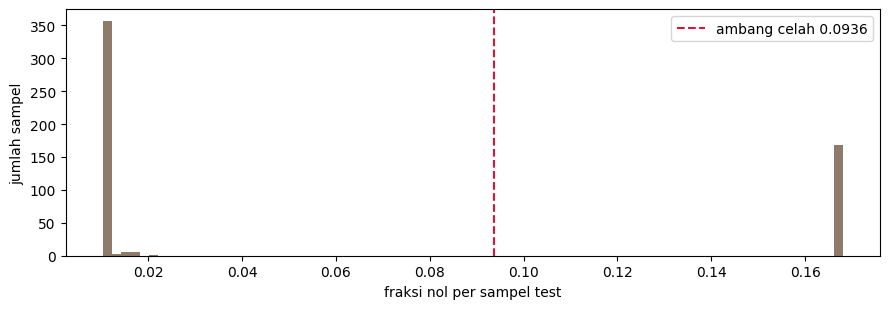

In [7]:
import matplotlib.pyplot as plt

test_zf = (TEST_HIST == 0).mean(axis=(1, 2))
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(test_zf, bins=80, color='#8E7B6B')
ax.axvline(0.0936, color='crimson', linestyle='--', label='ambang celah 0.0936')
ax.set_xlabel('fraksi nol per sampel test')
ax.set_ylabel('jumlah sampel')
ax.legend()
plt.tight_layout()
plt.show()

> ### Insights
> - Histogram fraksi nol test berbentuk dua gugus terpisah bersih tanpa satu pun sampel di zona abu-abu, sehingga *routing* regime praktis bebas galat.
> - Komposisi 372/168 dipakai sebagai bobot tetap saat menghitung skor CV tertimbang, meniru campuran regime di *leaderboard*.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="6"></a>
# **6. Statistik Ruas dan Anchor Mean-Reversion**

Statistik per ruas dihitung hanya dari nilai *live* (kecepatan > 0) pada prefix *train* yang aman terhadap *fold*: rerata, deviasi baku, kuartil bawah, fraksi nol, dan koefisien *mean-reversion* per horizon. Koefisien per ruas di-*shrink* ke median regime supaya ruas dengan sedikit data tidak liar, lalu dipotong ke [0, 1].

*Anchor* per horizon: `anchor_h = road_mean + c_road_h * (lag0 - road_mean)`. Ruas tanpa data *live* memakai *fallback* rerata global regime.

In [8]:
def fit_road_stats(series, horizons, shrink=200.0, eps=1e-8):
    """Statistik per ruas dari prefix train [T, N], hanya nilai live (> 0).

    Mengembalikan dict berisi mean, std, q25, zero_frac, coef [H, N], always_zero.
    """
    s = np.asarray(series, dtype=np.float32)
    live = s > 0
    n_live = live.sum(axis=0)
    glob_mean = float(s[live].mean()) if live.any() else 0.0
    glob_std = float(s[live].std()) if live.any() else 1.0
    safe_n = np.maximum(n_live, 1)
    mean = (s * live).sum(axis=0) / safe_n
    ex2 = (s * s * live).sum(axis=0) / safe_n
    std = np.sqrt(np.maximum(ex2 - mean ** 2, 1e-6))
    s_nan = np.where(live, s, np.nan)
    with np.errstate(all='ignore'):
        q25 = np.nanpercentile(s_nan, 25, axis=0)
    has_live = n_live > 0
    mean = np.where(has_live, mean, glob_mean).astype(np.float32)
    std = np.where(has_live, std, glob_std).astype(np.float32)
    q25 = np.where(has_live, np.nan_to_num(q25, nan=glob_mean), glob_mean).astype(np.float32)
    zero_frac = 1.0 - n_live / len(s)

    coef = np.zeros((len(horizons), s.shape[1]), dtype=np.float32)
    for j, h in enumerate(horizons):
        x, y = s[:-h], s[h:]
        pair = (x > 0) & (y > 0)
        dx = np.where(pair, x - mean[None, :], 0.0)
        dy = np.where(pair, y - mean[None, :], 0.0)
        num = (dx * dy).sum(axis=0)
        den = (dx * dx).sum(axis=0)
        n_pair = pair.sum(axis=0)
        c_raw = num / np.maximum(den, eps)
        ok = n_pair >= 50
        c_med = float(np.median(c_raw[ok])) if ok.any() else 0.5
        c = (n_pair * c_raw + shrink * c_med) / (n_pair + shrink)
        coef[j] = np.clip(np.where(has_live, c, c_med), 0.0, 1.0)
    return {'mean': mean, 'std': std, 'q25': q25,
            'zero_frac': zero_frac.astype(np.float32),
            'coef': coef, 'always_zero': ~has_live,
            'glob_mean': glob_mean, 'glob_std': glob_std}


def compute_anchors(lag0, stats):
    """Anchor mean-reversion [B, N, H] dari kecepatan terakhir [B, N]."""
    dev = lag0[:, :, None] - stats['mean'][None, :, None]
    return (stats['mean'][None, :, None] + stats['coef'].T[None, :, :] * dev).astype(np.float32)

In [9]:
STATS_FULL = {name: fit_road_stats(arr, CFG.HORIZONS, CFG.COEF_SHRINK)
              for name, arr in SPEED.items()}
for name, st in STATS_FULL.items():
    print(f"{name}: rerata live {st['glob_mean']:.2f}, ruas selalu nol {int(st['always_zero'].sum())}, "
          f"median coef h5/h10/h15 = "
          + ' / '.join(f'{np.median(st["coef"][j]):.3f}' for j in range(3)))

m1: rerata live 55.57, ruas selalu nol 13, median coef h5/h10/h15 = 0.564 / 0.480 / 0.421
m2: rerata live 59.02, ruas selalu nol 210, median coef h5/h10/h15 = 0.493 / 0.453 / 0.415


> ### Insights
> - Median koefisien *mean-reversion* menurun seiring horizon dan berbeda antar regime, konsisten dengan audit (m1 lebih *mean-reverting* jangka pendek daripada m2).
> - Ruas selalu nol berbeda jauh antar regime (13 vs 210), menegaskan bahwa statistik per regime wajib dan *mask* tidak boleh digabung.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="7"></a>
# **7. Fitur Teks Atomik**

Audit teks menunjukkan 10 kata kunci atomik mencakup >99.9% kalimat, sedangkan *TF-IDF*/*embedding*/pasangan event-lokasi tidak memberi nilai tambah dan rawan *overfit*. Fitur teks per sampel: 10 hitungan kata kunci plus jumlah kalimat. Fitur *lag* teks antar sampel test dilarang karena urutan test tidak kontinu (Jaccard median 0.245).

In [10]:
TEXT_KEYWORDS = ('road closure', 'accident', 'construction', 'traffic control',
                 'prohibit left turn', 'announcement', 'road obstruction',
                 'broken down vehicle', 'snow cover', 'water')
TEXT_DIM = len(TEXT_KEYWORDS) + 1


def count_text_features(text):
    """Hitung fitur teks atomik dari satu entri teks."""
    low = str(text).lower()
    counts = [float(low.count(k)) for k in TEXT_KEYWORDS]
    counts.append(float(low.count('.')))
    return counts


def build_text_matrix(text_dict, key_fmt, n):
    out = np.zeros((n, TEXT_DIM), dtype=np.float32)
    for i in range(n):
        out[i] = count_text_features(text_dict[key_fmt(i)])
    return out


TEXT_TRAIN = {
    'm1': build_text_matrix(TEXT_M1, lambda i: f'm1_{i + 1}', 11160),
    'm2': build_text_matrix(TEXT_M2, lambda i: f'm2_{i + 1}', 5039),
}
TEXT_TEST = build_text_matrix(TEXT_TEST_RAW, lambda i: f'test_{i:05d}', 540)
for name, mat in TEXT_TRAIN.items():
    print(name, 'teks: rata-rata hitungan per kata kunci =',
          np.round(mat.mean(axis=0), 2).tolist())
print('test teks: rata-rata =', np.round(TEXT_TEST.mean(axis=0), 2).tolist())

m1 teks: rata-rata hitungan per kata kunci = [17.649999618530273, 7.820000171661377, 5.539999961853027, 1.309999942779541, 1.0, 0.05999999865889549, 0.07000000029802322, 0.11999999731779099, 0.0, 0.03999999910593033, 28.75]
m2 teks: rata-rata hitungan per kata kunci = [19.030000686645508, 3.7200000286102295, 7.610000133514404, 2.0, 1.0800000429153442, 1.2899999618530273, 0.12999999523162842, 0.05999999865889549, 0.10000000149011612, 0.05000000074505806, 29.5]
test teks: rata-rata = [18.520000457763672, 7.860000133514404, 6.53000020980835, 1.590000033378601, 0.7300000190734863, 0.3499999940395355, 0.10000000149011612, 0.09000000357627869, 0.03999999910593033, 0.03999999910593033, 30.549999237060547]


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="8"></a>
# **8. Pembangun Fitur Bersama**

Satu fungsi `build_features` dipakai identik untuk *training* dan test: masukan jendela `[B, 15, N]`, fitur teks `[B, TEXT_DIM]`, dan statistik regime, keluaran matriks fitur `[B, N, F]` plus *anchor* `[B, N, 3]`. Ini menjamin paritas *train*/test tanpa duplikasi logika.

Kelompok fitur (semua terbukti lewat ablasi atau berbiaya sangat rendah):
- **Temporal lokal**: lag, rerata bergulir 3/5/15, deviasi baku, min/max, selisih 1/3/5/10/14 langkah, jumlah nol jendela.
- **Terpusat ruas**: deviasi terhadap rerata ruas, *z-score*, *flag* kemacetan (< 40 dan < kuartil bawah ruas).
- ***Global network state***: rerata *live* jaringan pada beberapa skala, tren, porsi ruas lambat, fraksi nol sampel.
- **Graf ringan**: 2 kolom *neighbor anomaly* (deviasi tetangga terhadap rerata ruasnya).
- **Identitas ruas**: `road_id` kategorikal, baris/kolom grid 36x36, metadata agregat (panjang total, jumlah *link*, centroid, bentang, kelas jalan, *formway*), statistik ruas per regime.
- **Teks**: 10 hitungan kata kunci + jumlah kalimat (sama untuk semua ruas dalam satu sampel).

In [11]:
def build_static_features(roads, active_mask, n_roads):
    """Metadata agregat per ruas: seluruh link digabung, bukan hanya link pertama."""
    grid = np.zeros((n_roads, 2), dtype=np.float32)
    pos = np.flatnonzero(active_mask)
    assert len(pos) == n_roads
    side = int(np.sqrt(len(active_mask)))
    grid[:, 0] = pos // side
    grid[:, 1] = pos % side

    feats = np.zeros((n_roads, 9), dtype=np.float32)
    cats = np.zeros((n_roads, 2), dtype=np.int32)
    for i, links in enumerate(roads):
        lengths = np.array([l.get('length', 0.0) for l in links], dtype=np.float64)
        lons, lats = [], []
        for l in links:
            cl = l.get('coordList', [])
            lons.extend(cl[0::2])
            lats.extend(cl[1::2])
        lons = np.array(lons if lons else [0.0])
        lats = np.array(lats if lats else [0.0])
        feats[i] = (len(links), lengths.sum(), lengths.mean() if len(lengths) else 0.0,
                    lons.mean(), lats.mean(), lons.max() - lons.min(),
                    lats.max() - lats.min(), grid[i, 0], grid[i, 1])
        rc = [l.get('roadclass', -1) for l in links]
        fw = [l.get('formway', -1) for l in links]
        cats[i, 0] = max(set(rc), key=rc.count)
        cats[i, 1] = max(set(fw), key=fw.count)
    return feats, cats


def build_graph_operator(adjacency):
    """Operator rata-rata tetangga simetris (tanpa self-loop), dinormalisasi baris."""
    a = (np.asarray(adjacency) != 0).astype(np.float32)
    np.fill_diagonal(a, 0.0)
    sym = np.maximum(a, a.T)
    deg = sym.sum(axis=1, keepdims=True)
    return sym / np.maximum(deg, 1.0)


STATIC_NUM, STATIC_CAT = build_static_features(ROADS, ACTIVE_MASK, N_ROADS)
NB_OP = build_graph_operator(ADJ)
print('metadata statis :', STATIC_NUM.shape, '| kategori :', STATIC_CAT.shape)
print('derajat tetangga: median',
      int(np.median((NB_OP > 0).sum(axis=1))), ', terisolasi',
      int(((NB_OP > 0).sum(axis=1) == 0).sum()))

metadata statis : (1260, 9) | kategori : (1260, 2)
derajat tetangga: median 3 , terisolasi 13


In [12]:
FEATURE_NAMES = (
    ['lag0', 'mean3', 'mean5', 'mean15', 'std5', 'std15', 'min15', 'max15', 'range15',
     'diff1', 'diff3', 'diff5', 'diff10', 'diff14', 'zeros15',
     'dev0', 'dev5', 'z0', 'cong40', 'cong_q25', 'below40_5'] +
    ['g_lag0', 'g_mean5', 'g_mean15', 'g_d1', 'g_d5', 'g_d14', 'g_low40', 'sample_zf'] +
    (['nb1_dev0', 'nb1_dev5'] if CFG.USE_GRAPH else []) +
    ['road_id', 'grid_row', 'grid_col', 'n_links', 'total_len', 'mean_len',
     'lon', 'lat', 'lon_span', 'lat_span', 'roadclass', 'formway',
     'road_mean', 'road_std', 'road_q25', 'road_zf'] +
    [f'txt_{i}' for i in range(TEXT_DIM)] +
    ['anchor_h', 'coef_h']
)
CAT_FEATURES = ['road_id', 'roadclass', 'formway']
CAT_IDX = [FEATURE_NAMES.index(c) for c in CAT_FEATURES]
N_FEATURES = len(FEATURE_NAMES)
print(f'{N_FEATURES} fitur, kategorikal: {CAT_FEATURES}')


def build_features(windows, text_feats, stats, static_num, static_cat, nb_op, use_graph=True):
    """Bangun fitur [B, N, F] dan anchor [B, N, H] dari jendela [B, H15, N].

    Dua kolom terakhir (anchor_h, coef_h) diisi nol di sini dan
    diganti per horizon sebelum training/prediksi.
    """
    w = np.asarray(windows, dtype=np.float32)
    B, H, N = w.shape
    lag0 = w[:, -1, :]
    rm = stats['mean'][None, :]
    rs = stats['std'][None, :]
    cols = []

    mean5 = w[:, -5:, :].mean(axis=1)
    cols.append(lag0)
    cols.append(w[:, -3:, :].mean(axis=1))
    cols.append(mean5)
    cols.append(w.mean(axis=1))
    cols.append(w[:, -5:, :].std(axis=1))
    cols.append(w.std(axis=1))
    w_min, w_max = w.min(axis=1), w.max(axis=1)
    cols.extend([w_min, w_max, w_max - w_min])
    for back in (2, 4, 6, 11, 15):
        cols.append(lag0 - w[:, -back, :])
    cols.append((w == 0).sum(axis=1).astype(np.float32))

    dev0 = lag0 - rm
    dev5 = mean5 - rm
    cols.extend([dev0, dev5, dev0 / rs,
                 (lag0 < 40).astype(np.float32),
                 (lag0 < stats['q25'][None, :]).astype(np.float32),
                 (((w[:, -5:, :] > 0) & (w[:, -5:, :] < 40)).sum(axis=1)).astype(np.float32)])

    live = w > 0
    n_live = np.maximum(live.sum(axis=2), 1)
    g = (w * live).sum(axis=2) / n_live
    g0 = g[:, -1]
    low40 = ((live[:, -1, :]) & (lag0 < 40)).sum(axis=1) / np.maximum(live[:, -1, :].sum(axis=1), 1)
    sample_zf = (w == 0).mean(axis=(1, 2))
    for vec in (g0, g[:, -5:].mean(axis=1), g.mean(axis=1),
                g0 - g[:, -2], g0 - g[:, -6], g0 - g[:, 0], low40, sample_zf):
        cols.append(np.repeat(vec[:, None], N, axis=1).astype(np.float32))

    if use_graph:
        cols.append(dev0 @ nb_op.T)
        cols.append(dev5 @ nb_op.T)

    static_all = np.concatenate([
        np.arange(N, dtype=np.float32)[:, None],
        static_num[:, 7:9],
        static_num[:, 0:1], static_num[:, 1:2], static_num[:, 2:3],
        static_num[:, 3:4], static_num[:, 4:5], static_num[:, 5:6], static_num[:, 6:7],
        static_cat.astype(np.float32),
        stats['mean'][:, None], stats['std'][:, None],
        stats['q25'][:, None], stats['zero_frac'][:, None]], axis=1)
    for k in range(static_all.shape[1]):
        cols.append(np.repeat(static_all[None, :, k], B, axis=0))

    for k in range(text_feats.shape[1]):
        cols.append(np.repeat(text_feats[:, k:k + 1], N, axis=1).astype(np.float32))

    cols.append(np.zeros((B, N), dtype=np.float32))   # anchor_h, diisi per horizon
    cols.append(np.zeros((B, N), dtype=np.float32))   # coef_h, diisi per horizon

    X = np.stack(cols, axis=2).astype(np.float32)
    assert X.shape == (B, N, N_FEATURES), f'jumlah fitur {X.shape[2]} != {N_FEATURES}'
    anchors = compute_anchors(lag0, stats)
    return X, anchors

60 fitur, kategorikal: ['road_id', 'roadclass', 'formway']


In [13]:
def assemble_training(series, text_mat, origins, stats, horizons, chunk=256):
    """Susun matriks fitur baris live untuk satu regime.

    Mengembalikan X [R, F], anchors [R, H], targets [R, H], origin_idx [R].
    Baris dengan lag0 == 0 dibuang (aturan nol).
    """
    xs, ans, ys, oi = [], [], [], []
    origins = np.asarray(origins)
    for s0 in range(0, len(origins), chunk):
        block = origins[s0:s0 + chunk]
        hist, targ = make_windows(series, block, CFG.HISTORY, horizons)
        X, A = build_features(hist, text_mat[block], stats,
                              STATIC_NUM, STATIC_CAT, NB_OP, CFG.USE_GRAPH)
        lag0 = hist[:, -1, :]
        keep = (lag0 > 0).reshape(-1)
        xs.append(X.reshape(-1, N_FEATURES)[keep])
        ans.append(A.reshape(-1, len(horizons))[keep])
        ys.append(targ.transpose(0, 2, 1).reshape(-1, len(horizons))[keep])
        oi.append(np.repeat(block, X.shape[1])[keep])
    return (np.concatenate(xs), np.concatenate(ans),
            np.concatenate(ys), np.concatenate(oi))


def recency_weights(origin_idx, n_time, lo, hi):
    """Bobot sampel linear dari lo (awal) ke hi (akhir) menurut indeks waktu origin."""
    frac = origin_idx / max(n_time - 1, 1)
    return (lo + (hi - lo) * frac).astype(np.float32)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="9"></a>
# **9. Validasi Silang 3 Fold**

Tiga *fold* waktu ekspansif per regime (batas 55/70/85/100% deret), skor dihitung persis seperti metrik kompetisi: *MSE* atas semua ruas dan horizon, termasuk baris aturan nol, lalu ditimbang 372/540 (m1) dan 168/540 (m2). *Early stopping* memakai subset origin validasi; `best_iteration` tiap *fold* dipakai untuk menentukan jumlah pohon *training* final.

Sebagai pembanding ditampilkan juga *MSE anchor* saja (referensi audit: sekitar 40.3) supaya kontribusi model residual terlihat langsung.

In [14]:
def fold_bounds(n_time, fold):
    a, b = CFG.FOLD_FRACS[fold]
    return int(n_time * a), int(n_time * b)


def val_origins(tr_end, va_end, stride):
    return np.arange(tr_end + CFG.HISTORY - 1, va_end - max(CFG.HORIZONS), stride)


def train_origins(tr_end, stride):
    return np.arange(CFG.HISTORY - 1, tr_end - max(CFG.HORIZONS), stride)


def eval_regime_mse(models, series, text_mat, origins, stats):
    """MSE per horizon pada origins validasi, memakai metrik kompetisi penuh."""
    hist, targ = make_windows(series, origins, CFG.HISTORY, CFG.HORIZONS)
    X, A = build_features(hist, text_mat[origins], stats,
                          STATIC_NUM, STATIC_CAT, NB_OP, CFG.USE_GRAPH)
    B = len(origins)
    lag0 = hist[:, -1, :]
    Xf = X.reshape(-1, N_FEATURES)
    errs = []
    for j, h in enumerate(CFG.HORIZONS):
        Xf[:, -2] = A[:, :, j].reshape(-1)
        Xf[:, -1] = np.repeat(stats['coef'][j][None, :], B, axis=0).reshape(-1)
        res = models[j].predict(Xf, num_iteration=models[j].best_iteration)
        pred = A[:, :, j].reshape(-1) + res
        pred = np.clip(pred, *CFG.PREDICTION_CLIP)
        pred = np.where(lag0.reshape(-1) == 0, 0.0, pred)
        errs.append(float(((pred - targ[:, j, :].reshape(-1)) ** 2).mean()))
    anchor_errs = []
    for j in range(len(CFG.HORIZONS)):
        base = np.where(lag0 == 0, 0.0, A[:, :, j])
        base = np.clip(base, *CFG.PREDICTION_CLIP)
        anchor_errs.append(float(((base - targ[:, j, :]) ** 2).mean()))
    return errs, anchor_errs

In [15]:
def train_fold_models(series, text_mat, stats, tr_end, name, stride, rounds,
                     es_origins=None):
    """Latih 3 model LightGBM residual (satu per horizon) pada prefix train."""
    tr_orig = train_origins(tr_end, stride)
    X, A, Y, OI = assemble_training(series, text_mat, tr_orig, stats, CFG.HORIZONS)
    weight = None
    if name == 'm2' and CFG.M2_RECENCY:
        weight = recency_weights(OI, tr_end, *CFG.M2_RECENCY_RANGE)
    Xv = Av = Yv = None
    if es_origins is not None and len(es_origins) > 0:
        hist, targ = make_windows(series, es_origins, CFG.HISTORY, CFG.HORIZONS)
        Xv, Av = build_features(hist, text_mat[es_origins], stats,
                                STATIC_NUM, STATIC_CAT, NB_OP, CFG.USE_GRAPH)
        keepv = (hist[:, -1, :] > 0).reshape(-1)
        Xv = Xv.reshape(-1, N_FEATURES)[keepv]
        Av = Av.reshape(-1, len(CFG.HORIZONS))[keepv]
        Yv = targ.transpose(0, 2, 1).reshape(-1, len(CFG.HORIZONS))[keepv]
    models = []
    params = dict(CFG.LGB_PARAMS, num_threads=N_THREADS)
    for j, h in enumerate(CFG.HORIZONS):
        X[:, -2] = A[:, j]
        X[:, -1] = stats['coef'][j][np.clip(X[:, CAT_IDX[0]].astype(np.int64), 0, N_ROADS - 1)]
        dtrain = lgb.Dataset(X, label=Y[:, j] - A[:, j], weight=weight,
                             feature_name=FEATURE_NAMES,
                             categorical_feature=CAT_FEATURES)
        callbacks = [lgb.log_evaluation(0)]
        valid_sets = []
        if Xv is not None:
            Xv[:, -2] = Av[:, j]
            Xv[:, -1] = stats['coef'][j][np.clip(Xv[:, CAT_IDX[0]].astype(np.int64), 0, N_ROADS - 1)]
            valid_sets = [lgb.Dataset(Xv, label=Yv[:, j] - Av[:, j], reference=dtrain)]
            callbacks.append(lgb.early_stopping(CFG.EARLY_STOP, verbose=False))
        booster = lgb.train(params, dtrain, num_boost_round=rounds,
                            valid_sets=valid_sets, callbacks=callbacks)
        models.append(booster)
        used = booster.best_iteration or rounds
        print(f'    {name} h{h}: {X.shape[0]:,} baris, pohon {used}')
    del X, A, Y
    return models

In [16]:
IS_SMOKE = CFG.RUN_MODE == 'smoke'
EFFECTIVE_FOLDS = [2] if IS_SMOKE else list(CFG.FOLDS)
STRIDES = CFG.SMOKE_STRIDE if IS_SMOKE else CFG.CV_STRIDE
MAX_ROUNDS = CFG.SMOKE_ROUNDS if IS_SMOKE else CFG.MAX_ROUNDS

CV_ROWS = []
BEST_ITERS = {(name, j): [] for name in SPEED for j in range(3)}
t_start = time.time()
for fold in EFFECTIVE_FOLDS:
    for name, series in SPEED.items():
        tr_end, va_end = fold_bounds(len(series), fold)
        stats = fit_road_stats(series[:tr_end], CFG.HORIZONS, CFG.COEF_SHRINK)
        es_orig = val_origins(tr_end, va_end, CFG.ES_STRIDE)
        print(f'== fold {fold} {name}: train sampai {tr_end}, val sampai {va_end} ==')
        models = train_fold_models(series, TEXT_TRAIN[name], stats, tr_end,
                                   name, STRIDES[name], MAX_ROUNDS, es_orig)
        for j in range(3):
            bi = models[j].best_iteration
            BEST_ITERS[(name, j)].append(bi if bi and bi > 0 else MAX_ROUNDS)
        va_orig = val_origins(tr_end, va_end, CFG.EVAL_STRIDE)
        errs, a_errs = eval_regime_mse(models, series, TEXT_TRAIN[name], va_orig, stats)
        CV_ROWS.append({'fold': fold, 'regime': name,
                        'mse': float(np.mean(errs)), 'anchor': float(np.mean(a_errs)),
                        **{f'h{h}': errs[j] for j, h in enumerate(CFG.HORIZONS)}})
        print(f'   fold {fold} {name}: v3 {np.mean(errs):.4f} vs anchor {np.mean(a_errs):.4f} '
              f'(per-h: ' + ' / '.join(f'{e:.3f}' for e in errs) + ')')
        del models
print(f'CV selesai dalam {(time.time() - t_start) / 60:.1f} menit')

== fold 0 m1: train sampai 6138, val sampai 7811 ==
    m1 h5: 1,523,795 baris, pohon 99
    m1 h10: 1,523,795 baris, pohon 88
    m1 h15: 1,523,795 baris, pohon 77
   fold 0 m1: v3 40.5295 vs anchor 49.7857 (per-h: 33.967 / 41.484 / 46.137)
== fold 0 m2: train sampai 2771, val sampai 3527 ==
    m2 h5: 959,594 baris, pohon 102
    m2 h10: 959,594 baris, pohon 121
    m2 h15: 959,594 baris, pohon 149
   fold 0 m2: v3 26.8104 vs anchor 33.7094 (per-h: 23.307 / 26.890 / 30.234)
== fold 1 m1: train sampai 7811, val sampai 9486 ==
    m1 h5: 1,941,495 baris, pohon 90
    m1 h10: 1,941,495 baris, pohon 70
    m1 h15: 1,941,495 baris, pohon 84
   fold 1 m1: v3 36.3584 vs anchor 44.2936 (per-h: 31.107 / 36.815 / 41.153)
== fold 1 m2: train sampai 3527, val sampai 4283 ==
    m2 h5: 1,224,194 baris, pohon 150
    m2 h10: 1,224,194 baris, pohon 124
    m2 h15: 1,224,194 baris, pohon 109
   fold 1 m2: v3 24.5997 vs anchor 31.0184 (per-h: 22.046 / 24.801 / 26.952)
== fold 2 m1: train sampai 9486,

         anchor               mse         
regime       m1       m2       m1       m2
fold                                      
0       49.7857  33.7094  40.5295  26.8104
1       44.2936  31.0184  36.3584  24.5997
2       40.5083  38.4157  33.6539  29.1461

CV tertimbang per fold : [36.2613, 32.7001, 32.2515]
CV v3 tertimbang       : 33.7376 (std antar fold 2.197)
CV anchor tertimbang   : 41.6017
Referensi: ridge audit 35.42, v2 LB 39.256, peringkat 1 LB 34.225


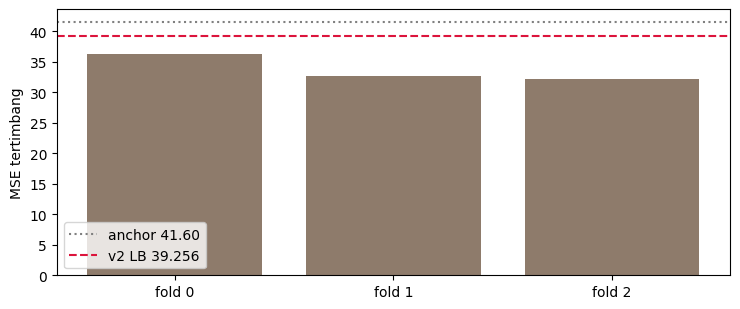

In [17]:
CV_DF = pd.DataFrame(CV_ROWS)
piv = CV_DF.pivot_table(index='fold', columns='regime', values=['mse', 'anchor'])
weighted = {}
for key in ('mse', 'anchor'):
    weighted[key] = sum(REGIME_W[n] * CV_DF[CV_DF.regime == n][key].mean() for n in SPEED)
per_fold_w = CV_DF.groupby('fold').apply(
    lambda d: sum(REGIME_W[r] * d[d.regime == r]['mse'].iloc[0] for r in SPEED))
print(piv.round(4))
print()
print('CV tertimbang per fold :', [round(v, 4) for v in per_fold_w.tolist()])
CV_WEIGHTED = float(weighted['mse'])
CV_ANCHOR = float(weighted['anchor'])
print(f'CV v3 tertimbang       : {CV_WEIGHTED:.4f} (std antar fold {per_fold_w.std():.3f})')
print(f'CV anchor tertimbang   : {CV_ANCHOR:.4f}')
print(f'Referensi: ridge audit 35.42, v2 LB {CFG.ANCHOR_V2_LB}, peringkat 1 LB 34.225')

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.bar([f'fold {f}' for f in per_fold_w.index], per_fold_w.values, color='#8E7B6B')
ax.axhline(CV_ANCHOR, color='gray', linestyle=':', label=f'anchor {CV_ANCHOR:.2f}')
ax.axhline(CFG.ANCHOR_V2_LB, color='crimson', linestyle='--', label='v2 LB 39.256')
ax.set_ylabel('MSE tertimbang')
ax.legend()
plt.tight_layout()
plt.show()

> ### Insights
> - Kontribusi model residual terlihat dari selisih batang CV terhadap garis *anchor*; berdasarkan probe *ridge*, selisih sehat berada di kisaran 4 sampai 5 poin *MSE*.
> - Variasi antar *fold* wajar (audit mencatat sekitar 1.3 sampai 2.9); keputusan submit memakai rata-rata tertimbang, bukan satu *fold* terbaik.

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="10"></a>
# **10. Gerbang Validasi Submisi**

Slot submisi tersisa sedikit, jadi *submission* hanya dibuat bila CV tertimbang v3:
1. berada di bawah `GATE_MAX_CV` (37.5, jauh di bawah proxy v2 39.256), dan
2. mengalahkan *anchor* minimal `GATE_MIN_VS_ANCHOR` (2.0 poin).

Kalau gerbang gagal, notebook tetap selesai tanpa menulis `submission.csv` supaya slot tidak terbakar sia-sia.

In [18]:
GATE_A = CV_WEIGHTED <= CFG.GATE_MAX_CV
GATE_B = (CV_ANCHOR - CV_WEIGHTED) >= CFG.GATE_MIN_VS_ANCHOR
SUBMIT_CANDIDATE = bool(GATE_A and GATE_B)
print(f'Gerbang A (CV {CV_WEIGHTED:.4f} <= {CFG.GATE_MAX_CV})            : {GATE_A}')
print(f'Gerbang B (anchor - v3 = {CV_ANCHOR - CV_WEIGHTED:.4f} >= {CFG.GATE_MIN_VS_ANCHOR}) : {GATE_B}')
print('LOLOS GERBANG' if SUBMIT_CANDIDATE else 'GAGAL GERBANG: jangan pakai slot submisi')

Gerbang A (CV 33.7376 <= 37.5)            : True
Gerbang B (anchor - v3 = 7.8641 >= 2.0) : True
LOLOS GERBANG


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="11"></a>
# **11. Pelatihan Final dan Submission**

Model final dilatih ulang pada **seluruh** data tiap regime (temuan audit: v1 menyia-nyiakan potongan validasi) dengan *stride* lebih rapat, jumlah pohon = median `best_iteration` CV dikali 1.1. Inferensi: sampel test dirutekan ke regime masing-masing, prediksi = *anchor* + residual, baris `lag0 == 0` dipulihkan jadi nol, lalu dipotong ke rentang valid. Urutan id `sample_submission.csv` dipertahankan persis.

In [19]:
def predict_test(models, stats, hist_raw, text_feats):
    """Prediksi test satu regime: hist_raw [S, H15, N] -> [S, N, 3]."""
    X, A = build_features(hist_raw, text_feats, stats,
                          STATIC_NUM, STATIC_CAT, NB_OP, CFG.USE_GRAPH)
    S = hist_raw.shape[0]
    lag0 = hist_raw[:, -1, :]
    Xf = X.reshape(-1, N_FEATURES)
    out = np.zeros((S, N_ROADS, 3), dtype=np.float32)
    for j in range(3):
        Xf[:, -2] = A[:, :, j].reshape(-1)
        Xf[:, -1] = np.repeat(stats['coef'][j][None, :], S, axis=0).reshape(-1)
        res = models[j].predict(Xf, num_iteration=models[j].best_iteration)
        pred = A[:, :, j].reshape(-1) + res
        pred = np.clip(pred, *CFG.PREDICTION_CLIP)
        pred = np.where(lag0.reshape(-1) == 0, 0.0, pred)
        out[:, :, j] = pred.reshape(S, N_ROADS)
    return out

In [20]:
if CFG.RUN_MODE == 'final' and (SUBMIT_CANDIDATE or CFG.FORCE_SUBMISSION):
    FINAL_PRED = np.zeros((540, 3, N_ROADS), dtype=np.float32)
    for name, series in SPEED.items():
        stats = STATS_FULL[name]
        rounds = {}
        for j in range(3):
            med = float(np.median(BEST_ITERS[(name, j)]))
            rounds[j] = int(np.clip(med * CFG.FINAL_ROUND_MULT, *CFG.FINAL_ROUND_RANGE))
        n_rounds = max(rounds.values())
        print(f'=== final {name}: stride {CFG.FINAL_STRIDE[name]}, pohon per horizon {rounds} ===')
        tr_orig = train_origins(len(series), CFG.FINAL_STRIDE[name])
        X, A, Y, OI = assemble_training(series, TEXT_TRAIN[name], tr_orig,
                                        stats, CFG.HORIZONS)
        weight = None
        if name == 'm2' and CFG.M2_RECENCY:
            weight = recency_weights(OI, len(series), *CFG.M2_RECENCY_RANGE)
        models = []
        params = dict(CFG.LGB_PARAMS, num_threads=N_THREADS)
        for j, h in enumerate(CFG.HORIZONS):
            X[:, -2] = A[:, j]
            X[:, -1] = stats['coef'][j][np.clip(X[:, CAT_IDX[0]].astype(np.int64), 0, N_ROADS - 1)]
            dtrain = lgb.Dataset(X, label=Y[:, j] - A[:, j], weight=weight,
                                 feature_name=FEATURE_NAMES,
                                 categorical_feature=CAT_FEATURES)
            booster = lgb.train(params, dtrain, num_boost_round=rounds[j],
                                callbacks=[lgb.log_evaluation(0)])
            models.append(booster)
            print(f'    {name} h{h}: {X.shape[0]:,} baris, {rounds[j]} pohon selesai')
        del X, A, Y
        idx = np.where(TEST_REGIME == name)[0]
        FINAL_PRED[idx] = predict_test(models, stats, TEST_HIST[idx],
                                       TEXT_TEST[idx]).transpose(0, 2, 1)
        for j, m in enumerate(models):
            m.save_model(str(WORK_DIR / f'final_{name}_h{CFG.HORIZONS[j]}.txt'))
        del models

    flat = FINAL_PRED.reshape(-1)
    assert np.isfinite(flat).all()
    assert flat.min() >= CFG.PREDICTION_CLIP[0] and flat.max() <= CFG.PREDICTION_CLIP[1]
    submission = pd.DataFrame({'id': SAMPLE_SUB['id'], 'speed': flat})
    assert len(submission) == 2041200
    assert submission['id'].iloc[0] == 'test_00000_h5_r0'
    assert submission['id'].iloc[-1] == 'test_00539_h15_r1259'
    assert submission['id'].equals(SAMPLE_SUB['id'])
    submission.to_csv(WORK_DIR / 'submission.csv', index=False)
    zero_share = float((flat == 0).mean())
    print(f'submission.csv tersimpan di {WORK_DIR} | porsi nol {100 * zero_share:.2f}%')
elif CFG.RUN_MODE == 'final':
    print('gerbang penerimaan GAGAL: submission tidak dibuat, jangan pakai slot submisi')
elif CFG.RUN_MODE == 'smoke':
    name = 'm2'
    stats = fit_road_stats(SPEED[name][:3000], CFG.HORIZONS, CFG.COEF_SHRINK)
    models = train_fold_models(SPEED[name], TEXT_TRAIN[name], stats, 3000,
                               name, CFG.SMOKE_STRIDE[name], CFG.SMOKE_ROUNDS)
    idx = np.where(TEST_REGIME == name)[0][:8]
    out = predict_test(models, stats, TEST_HIST[idx], TEXT_TEST[idx])
    assert out.shape == (len(idx), N_ROADS, 3) and np.isfinite(out).all()
    zero_ok = (out[TEST_HIST[idx][:, -1, :] == 0] == 0).all()
    assert zero_ok, 'aturan nol tidak diterapkan pada prediksi test'
    print('smoke: jalur training + inferensi + aturan nol tervalidasi (tanpa submission)')
else:
    print('mode cv selesai: periksa tabel CV dan gerbang, lalu jalankan RUN_MODE=final')

=== final m1: stride 2, pohon per horizon {0: 250, 1: 250, 2: 250} ===
    m1 h5: 6,940,488 baris, 250 pohon selesai
    m1 h10: 6,940,488 baris, 250 pohon selesai
    m1 h15: 6,940,488 baris, 250 pohon selesai
=== final m2: stride 1, pohon per horizon {0: 250, 1: 250, 2: 250} ===
    m2 h5: 5,260,156 baris, 250 pohon selesai
    m2 h10: 5,260,156 baris, 250 pohon selesai
    m2 h15: 5,260,156 baris, 250 pohon selesai
submission.csv tersimpan di /kaggle/working | porsi nol 5.94%


<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<a id="12"></a>
# **12. Kesimpulan dan Daftar Pustaka**

v3 mengganti model neural v2 dengan enam model *LightGBM* residual per (regime, horizon) di atas *anchor mean-reversion* per ruas, karena bukti audit menunjukkan sinyal terbesar ada pada fitur temporal lokal, *global network state*, dan identitas ruas, bukan pada arsitektur graf yang dalam. Seluruh keputusan fitur mengikuti hasil ablasi dan probe empiris, dan keputusan submit dijaga gerbang CV tertimbang.

1. Shao, Z., dkk. (2022). *Spatial-Temporal Identity: A Simple yet Effective Baseline for Multivariate Time Series Forecasting*. CIKM 2022.
2. Xie, Q., dkk. (2019). *"How do urban incidents affect traffic speed?" A Deep Graph Convolutional Network for Incident-driven Traffic Speed Prediction*. (dasar fitur kategori insiden dari teks)
3. Ke, G., dkk. (2017). *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. NeurIPS 2017.
4. Wang, H., dkk. (2024). *STGformer: Efficient Spatiotemporal Graph Transformer for Traffic Forecasting*. (ditinjau, ditolak untuk v3 karena biaya/risiko)

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">

<p style="text-align:center; color:gray">TrafficCast v3, dibangun untuk babak penyisihan Datathon 2026 Task 1.</p>

<hr style="border: 2px solid #8E7B6B; margin-top: 10px;">